# RunShell Input File Generator

In [2]:
%reload_ext autoreload
%autoreload 2


## create dir

In [634]:
import os
sim_name = 'clamped_ribbon'
sim_name = "open_disc"
# sim_name = 'open_annulus'
# sim_name = 'gamma_wide2'
cwd        = os.getcwd()
output_dir = os.path.join(cwd, 'NewSims', sim_name)
os.makedirs(output_dir, exist_ok=True)

# print(os.getcwd())
# print("Contents of", os.path.dirname(output_dir), "→", os.listdir(os.path.dirname(output_dir)))
# print("Contents of", output_dir, "→", os.listdir(output_dir))

# create mesh

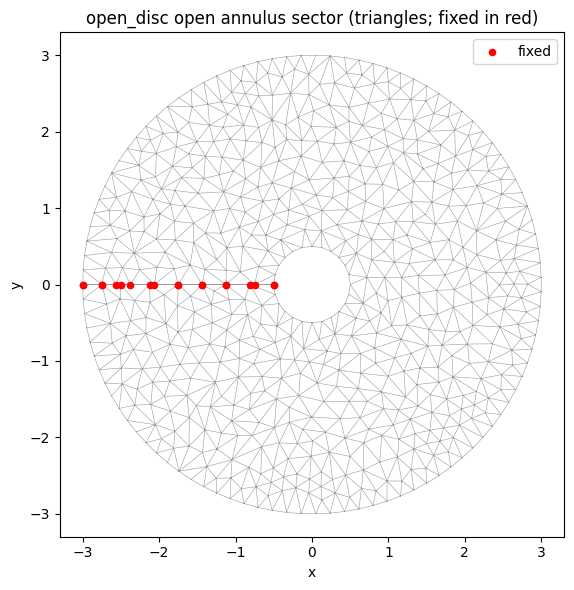

In [638]:
from generate_inputs import create_open_annulus_input_files
import numpy as np, os

if 1: 
    create_open_annulus_input_files(
        sim_name   = sim_name,
        output_dir = output_dir,
        r_in       = 0.5,
        r_out      = 3.0,
        vmin       = -np.pi,
        vmax       = np.pi,
        max_area   = 0.04,
        n_outer    = 100,
        n_inner    =  25,
        n_cut      =   2,
        band_dist  = 0.01
    )


In [639]:
from generate_inputs import *

if 0:
    domain_params = [ -5, 5, -0.5, 0.5 ]
    create_input_files(
        sim_name     = sim_name,
        output_dir   = output_dir,
        domain_params = domain_params,
        max_area     = 0.006,
        tols = (0.1,0)
    )
    if 'annulus' in sim_name:
        r_in = 0.1
        r_out = 1
        create_annulus_input_files(sim_name=sim_name, 
                                output_dir=output_dir,
                                r_in=r_in, r_out=r_out, 
                                max_area=0.01, 
                                n_outer=80, n_inner=10,
                                tols=(0, 0))


## Initial configuration

In [ ]:

from generate_inputs import plot_uv_surface, func_to_matlab_str
# for open disc:

x = lambda u,v: u*(np.cos(v))*sin((v+np.pi)/4)+0.1*(v**2-np.pi**2+np.cos(v/2))
y = lambda u,v: u*(np.sin(v))*sin((v+np.pi)/4)*(v**2-np.pi**2+np.cos(v/2))
z = lambda u,v: cos((v+np.pi)/4)*u

# for ribbon:
# x = lambda u,v: 0.9*(atan(u)-0.3*sin((pi/2+pi)*2*u/5))
# y = lambda u,v: v
# z = lambda u,v: 4*(10**4)*exp(-10/(1-(0.19999*u)**8))+8*np.cos(np.pi*atan(u)/5)*(exp(-1/(1-(0.1999*u)**2)))


# umin = domain_params[0]
# umax = domain_params[1]
# vmin = domain_params[2] 
# vmax = domain_params[3]
# plot_uv_surface(x, y, z, uxmin, umax, vmin, vmax)

xpos = func_to_matlab_str(x)  
ypos = func_to_matlab_str(y)
zpos = func_to_matlab_str(z) 
print(xpos)
print(ypos)
print(zpos)


u*sin(v/8+pi/8)*cos(v)
u*sin(v)*sin(v/8+pi/8)
u*cos(v/8+pi/8)


## GammaBar

In [649]:
import sympy as sp
from generate_inputs import calc_Gamma

u = sp.Symbol('u')
v = sp.Symbol('v')

#  example metric 
a = sp.Matrix([[1, 0], [0, u**2]])
Gamma_str = calc_Gamma(a, u, v)

print(Gamma_str)

[[['0', '0'], ['0', '-u']], [['0', '1./u'], ['1./u', '0']]]


## Params

In [650]:
thickness = 0.01
YoungsModulus = 10000000
PoisonRatio = 0.3
# "Lamme parameters" for connection energy
eta = 0
lambdaG = 0
muG = 0


## Generate RunShell input file

In [651]:
from generate_inputs import make_in_file
output_dir = os.path.join(cwd, 'NewSims', sim_name)
params = {
    'vertices_file': os.path.relpath(os.path.join(output_dir, f"{sim_name}_Vertices"), os.getcwd()),
    'faces_file':  os.path.relpath(os.path.join(output_dir, f"{sim_name}_Faces"), os.getcwd()),
    'loops':100000,
    'save_every':500,
    'abar':['1','0','0','u^2'], 
    'bbar':['0','0','0','0'],
    'thickness':str(thickness),
    'E':str(YoungsModulus),
    'nu':str(PoisonRatio),
    'pos0':[xpos,ypos,zpos],
    'eta':str(eta),
    'lambdaG':str(lambdaG),
    'muG':str(muG),
    'gamma':Gamma_str,
    'thickness_adjust':'10',
    'metric_adjust':'0.9',
    'connection_adjust':'2',
    'restart':'0'
}
in_file = make_in_file(params, output_dir, sim_name)



# Run

In [365]:
in_file_path = os.path.relpath(in_file, os.getcwd())
!./RunShell < {in_file_path}


[DEBUG] thickness_formula = "0.01"
[DEBUG] Input eta = 0
NonEuclideanShell::NonEuclideanShell()   Number of Nodes = 2116
[DEBUG] isfixed value summary:
   -2 → 2046 vertices
   -1 → 70 vertices
NonEuclideanShell::NonEuclideanShell()   Number of Faces = 3962
	The initial bending energy is 594.787894996435
	The initial stretching energy is 849011204.66044
	The initial connection energy is 0
0% Done: The current energy is 166985214.788219
 stretch = 166985101.506233 bend = 113.281985302705 conn = 0


OSError: [Errno 5] Input/output error

In [469]:
sim_name

'gamma14'